# 2MA100 - Devoir Maison 2

**Sorbonne Université - 19 avril 2021**

Les exercices de ce devoir maison noté sur 20 points doivent être rendus au choix au format **Notebook** (`.ipynb`) ou **Script** (`.py`) en un ou plusieurs fichiers au plus tard le **7 mai 2021** à 20h00 sur [moodle](https://moodle-sciences.upmc.fr/moodle-2020/).

**Attention Plagiat !**

Les devoirs maisons doivent être codés et rendus de manière individuelle. A titre d'information,
voici une définition du plagiat adaptée du [Memento de l'Université de Genève](https://memento.unige.ch/doc/0008/) :

*Le plagiat consiste à insérer, dans un travail académique, des formulations, des
phrases, des passages, des morceaux de code, des images, de même que des idées ou
analyses repris de travaux d'autres auteurs, en les faisant passer pour siens.*

En particulier, le copier-coller à partir de sources trouvées sur Internet ou sur des travaux d'autres
étudiant·es sans citer les sources est considéré comme du plagiat et implique une note zéro.
Le plagiat constitue également une tentative de tricherie sanctionnée par
le règlement de l'université. La solution est d'indiquer dans vos devoirs tout de ce qui ne vient
pas de vous en mentionnant les sources (page Internet, livres, autre étudiant·e,...). Tous les
fichiers rendus seront analysés automatiquement avec un logiciel de détection des similarités
(entre étudiant·es et depuis Internet).

Les modules Numpy et Matplotlib peuvent être utiles dans certains exercices :

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Exercice 1: Conjecture due à Euler

Euler a conjecturé en 1769 qu'au moins $k$ puissances $k$-ième d'entiers strictement positifs sont nécessaires pour que la somme soit elle-même une puissance $k$-ième. En d'autres termes si $n \geq 2$, $k \geq 1$, $a_1,a_2,\dots,a_n \geq 1$, et $b \geq 1$ sont des entiers tels que

$$
\sum_{i=1}^{n}(a_i)^k = b^k\,.
$$

alors nécessairement $n \geq k$.
Cette conjecture a été refutée en 1966 par Lander & Parkin ([doi:10.1090/S0002-9904-1966-11654-3](https://doi.org/10.1090/S0002-9904-1966-11654-3)) dans ce qui semble être le plus court article mathématique jamais écrit avec un contre-exemple pour $k=5$:

$$
27^5 + 84^5 + 110^5 + 133^5 = 144^5 \,.
$$

Le but est de montrer que ce contre-exemple est le plus simple possible, dans le sens où il est l'unique contre-exemple avec $k \leq 5$ et $b \leq 144$.

À noter que la conjecture est trivialement vraie pour $k=1$ et $k=2$ vu que par hypothèse $n \geq 2$, donc nécessairement $n \geq k$.

**a)**
Vérifier avec Python le contre-exemple ci-dessus.

**Solution:**
La compréhension de liste permet de faire la somme des puissances cinquièmes :

In [ ]:
sum([i**5 for i in [27,84,110,133]]) == 144**5



**b)**
Écrire une fonction `powers(bmax,k)` qui retourne l'ensemble de tous les entiers de de 1 à `bmax` élevés à la puissance `k`.

**Solution:**
Il suffit d'utiliser la compréhension d'ensemble:

In [ ]:
def powers(bmax,k):
    return {i**k for i in range(1,bmax+1)}



**c)**
Vérifier qu'il n'existe pas de contre-exemple avec $k=3$ et $b \leq 144$.

**Solution:**
Si on veut trouver un contre-exemple pour $k=3$, alors nécessairement $n=2$. Donc il suffit de tester toutes les combinaisons de deux entiers $a_1$ et $a_2$:

In [ ]:
def check3(bmax):
    out = set()
    integers3 = powers(bmax,3)
    for a1_3 in integers3:
        for a2_3 in integers3:
            somme = a1_3 + a2_3
            if somme in integers3:
                out.add(somme)
    return out

ce qui donne bien un ensemble vide pour $b \leq 144$:

In [ ]:
check3(144)



**d)**
Écrire une fonction `combinaisons(liste,n)` qui pour une liste d'entiers `liste` et un entier `n` retourne la liste de toutes les combinaisons avec répétitions de `n` entiers de `liste`
classés par ordre croissant. Par exemple `combinaisons([1,2,3,4],2)` doit retourner
`[(1,1), (1,2), (1,3), (1,4), (2,2), (2,3), (2,4), (3,3), (3,4), (4,4)]`.

**Indication:**
Utiliser une fonction récursive sur `n`.

**Solution:**
L'idée est de faire une fonction récursive ajoutant les nouveaux cas à la liste de sortie:

In [ ]:
def combinaisons(liste,n):
    if n==1:
        return [(i,) for i in liste]
    else:
        out = []
        for l in combinaisons(liste,n-1):
            for i in liste:
                if i >= l[-1]: out.append(l+(i,))
        return out

par exemple:

In [ ]:
combinaisons([4,3,2,1],2)



**e)**
Écrire une fonction `test(bmax,n,k)` qui pour trois entiers `bmax`, `n` et `k` donnés, itère sur toutes les combinaisons de `n` entiers retournés par `combinaisons` et vérifie si la somme de ces `n` entiers élevés à la puissance `k` est un entier présent dans la liste `powers(bmax,k)`. Utiliser cette fonction pour vérifier qu'il n'existe pas de contre-exemple à la conjecture d'Euler pour $k=4$ et $b \leq 144$. Suivant la puissance de votre ordinateur, il est possible de choisir également $k=5$ et donc de vérifier que le contre-exemple de l'introduction est bien le plus simple.

**Solution:**
Il suffit d'itérer sur les combinaisons:

In [ ]:
def test(bmax,n,k):
    out = set()
    p = powers(bmax,k)
    for c in combinaisons(range(1,bmax+1),n):
        somme = sum([i**k for i in c])
        if somme in p:
            out.add(c)
    return out

Pour $k=3,4$ on ne trouve pas de solution:

In [ ]:
test(144,2,3) | test(144,2,4) | test(144,3,4)

Pour $k=5$ on trouve bien la solution attendue:

In [ ]:
test(144,2,5) | test(144,3,5) | test(144,4,5)

À noter qu'il est possible d'améliorer un peu la performance de cet algorithme en faisant les combinaisons sur les puissances `powers(bmax,k)` plutôt que sur les entiers. Cet algorithme stocke en mémoire toutes les combinaisons, mais l'utilisation de la fonction `combinations_with_replacement` de `itertools` permet de s'affranchir de ce problème.

Pour $k=5$, la méthode précédente consistant à itérer sur toutes les combinaisons est plutôt lente. Une méthode plus rapide consiste à observer que l'ensemble des sommes du type:

$$
(a_1)^5 + (a_2)^5 + (a_3)^5 + (a_4)^5 \,,
$$

peut s'écrire comme $S_1 + S_2$ où $S_1$ et $S_2$ sont des sommes de deux entiers à la puissance cinq.

**f)**
Écrire une fonction `sum2(bmax,k)` qui retourne un dictionnaire ayant pour clefs les sommes $(a_1)^k+(a_2)^k$ avec la valeur associée $(a_1,a_2)$ pour $0 \leq a_1 \leq a_2 \leq$ `bmax`. On prendra soin d'enlever l'élément trivial zéro du dictionnaire. Dans la construction du dictionnaire, s'assurer qu'il est défini de manière unique dans le sens où il n'existe pas une autre valeur possible pour une clef existante. Tester `sum2(300,5)` et `sum2(300,3)`.

**Solution:**
L'idée est d'itérer sur toutes les valeurs de $a_1 \leq a_2$ et de tester si la clef n'existe pas déjà:

In [ ]:
def sum2(bmax,k):
    out = dict()
    # calcule les puissances k-ièmes
    integers_k = [i**k for i in range(1,bmax+1)]
    for i in range(1,bmax+1):
        for j in range(i,bmax+1):
            # pour ne pas recalcuer les puissances, équivalent à s = i**k + j**k
            s = integers_k[i-1] + integers_k[j-1]
            # cela ne doit jamais arriver, car dans ce cas le
            # dictionnaire serait pas définit de manière unique
            if s in out: raise ValueError("Dictionnaire pas unique")
            out[s] = (i,j)
    return out

Pour $k=5$, le dictionnaire semble défini de manière unique:

In [ ]:
sum2(300,5)

alors que pour $k=3$ ce n'est pas le cas:

In [14]:
sum2(300,3)

ValueError: Dictionnaire pas unique

À noter que la définition unique du dictionnaire pour `k=5` et n'importe quelle valeur de `bmax` est un problème mathématique ouvert.

**g)**
Utiliser le dictionnaire construit précédemment pour déterminer l'ensemble des contre-exemples pour $k=5$ et $b \leq 300$ en itérant sur tous les éléments de `power(bmax,5)` et de `sum2(bmax,5)`.

**Indication:**
Une implémentation optimale prend au plus quelques secondes à s'exécuter.

**Solution:**
Il est important d'itérer une seule fois sur `sum2(bmax,5)` et de tester l'appartenance de la différence à `sum2(bmax,5)`:

In [15]:
def test5(bmax):
    # liste des contre-exemples
    out = set()
    # dictionnaire des sommes de deux puissances cinquièmes
    s2 = sum2(bmax,5)
    # itération sur les puissances cinquièmes
    for p in powers(bmax,5):
        for s in s2:
            if p - s in s2:
                # valeurs du contre-exemple par ordre croissant
                l = sorted(s2[s] + s2[p-s])
                out.add(tuple(l))
    return out

Cela permet de découvrir un second contre-exemple:

In [16]:
test5(300)

{(27, 84, 110, 133), (54, 168, 220, 266)}

donné par:

$$
54^5 + 168^5 + 220^5 + 266^5 = 288^5 \,.
$$

À noter qu'il est possible d'optimiser ce code en triant préalablement le résultat de `sum2(bmax,5)` afin de sortir de la boucle lorsque c'est plus utile:

In [17]:
def test5opt(bmax):
    # liste des contre-exemples
    out = set()
    # dictionnaire des sommes de deux puissances cinquièmes
    s2 = sum2(bmax,5)
    s2sorted = sorted(s2)
    # itération sur les puissances cinquièmes
    for p in powers(bmax,5):
        for s in s2sorted:
            if p <= s: break
            if p - s in s2:
                # valeurs du contre-exemple par ordre croissant
                l = sorted(s2[s] + s2[p-s])
                out.add(tuple(l))
    return out

# Exercice 2: Ensemble de Mandelbrot

L'ensemble de Mandelbrot est défini comme l'ensemble des points $c\in\mathbb{C}$ pour lesquels la suite de nombres complexes définis récursivement par $z_0=0$ et

$$
z_{n+1} = z_n^2+c \,,
$$

est bornée.
Il est possible de montrer que $c\in\mathbb{C}$ est dans l'ensemble de Mandelbort si et seulement si $|z_n|\leq2$ pour tout entier $n$.

**a)**
Écrire une fonction `mandelbrot(c)` qui vérifie si le point $c\in\mathbb{C}$ est dans l'ensemble de Mandelbrot de manière approximative en testant les cent premiers termes.

**Solution:**
Il faut itérer la relation de récurrence et vérifier à chaque fois si oui ou non la condition $|z_n|\leq2$ est satisfaite:

In [19]:
def mandelbrot(c,max=100):
    z = 0
    for i in range(max):
        z = z**2+c
        if abs(z)>2:
            return False
    return True



**b)**
Tester la fonction précédente avec $c=0$ et $c=1+i$. Qu'est-il attendu théoriquement ?

**Solution:**
Le point $c=0$ est clairement dans l'ensemble de Mandelbort vu que $z_n=0$ pour tout $n$:

In [ ]:
mandelbrot(0)

Pour $c=1+i$, alors $z_1=1+i$ et $z_2=1+3i$ qui est de module plus grand que $2$ donc $c$ n'est pas dans l'ensemble de Mandelbort:

In [ ]:
mandelbrot(1+1j)



**c)**
Écrire une fonction qui génère un tableau de taille $N\times N$ représentant l'ensemble $c \in \big\{x+iy: x\in[-2,2] \; \text{et} \; y\in[-2,2]\big\}$ et qui retourne un tableau de booléens de taille $N\times N$ déterminant si le point associé est dans l'ensemble de Mandelbrot ou non.

**Solution:**
La première étape est de générer la grille; la seconde est de construire le tableau demandé:

In [18]:
def mandelbrot_set(N):
    # construction de la grille
    lst = np.linspace(-2,2,N)
    x, y = np.meshgrid(lst,lst)
    c = x + 1j*y
    # définition du tableau de sortie avec le type adapté
    out = np.zeros_like(c, dtype=type(mandelbrot(0)))
    # remplissage du tableau de sortie
    for i in range(N):
        for j in range(N):
            out[i,j] = mandelbrot(c[i,j])
    return out



**d)**
En utilisant la fonction précédente avec $N=101$, représenter graphiquement avec `imshow` une approximation de l'ensemble des points appartenant à l'ensemble de Mandelbort.

**Solution:**
Il suffit de représenter le tableau construit précédemment:

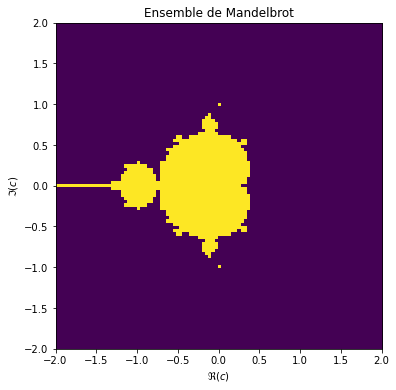

In [20]:
plt.figure(figsize=(6,6))
plt.title("Ensemble de Mandelbrot")
plt.xlabel(r"$\Re(c)$")
plt.ylabel(r"$\Im(c)$")
plt.imshow(mandelbrot_set(101), extent=[-2,2,-2,2])



**e)**
En adaptant les fonctions précédentes, représenter graphiquement le logarithme du nombre d'itérations nécessaires avant de ne plus satisfaire $|z_n|\leq 2$ au lieu d'un booléean.

**Solution:**
Il suffit de modifier la fonction `mandelbrot`:

In [21]:
def mandelbrot(c,max=100):
    z = 0
    for i in range(1,max+1):
        z = z**2+c
        if abs(z)>2:
            return np.log(i)
    return np.log(max)

et de tracer la même chose:

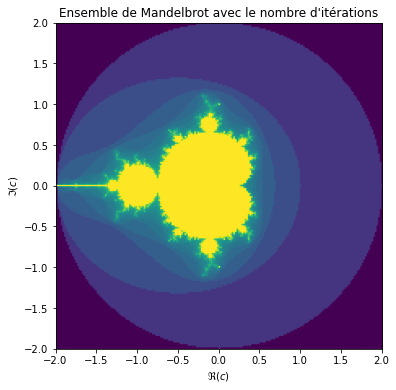

In [22]:
plt.figure(figsize=(6,6))
plt.title("Ensemble de Mandelbrot avec le nombre d'itérations")
plt.xlabel(r"$\Re(c)$")
plt.ylabel(r"$\Im(c)$")
plt.imshow(mandelbrot_set(201), extent=[-2,2,-2,2])



<center>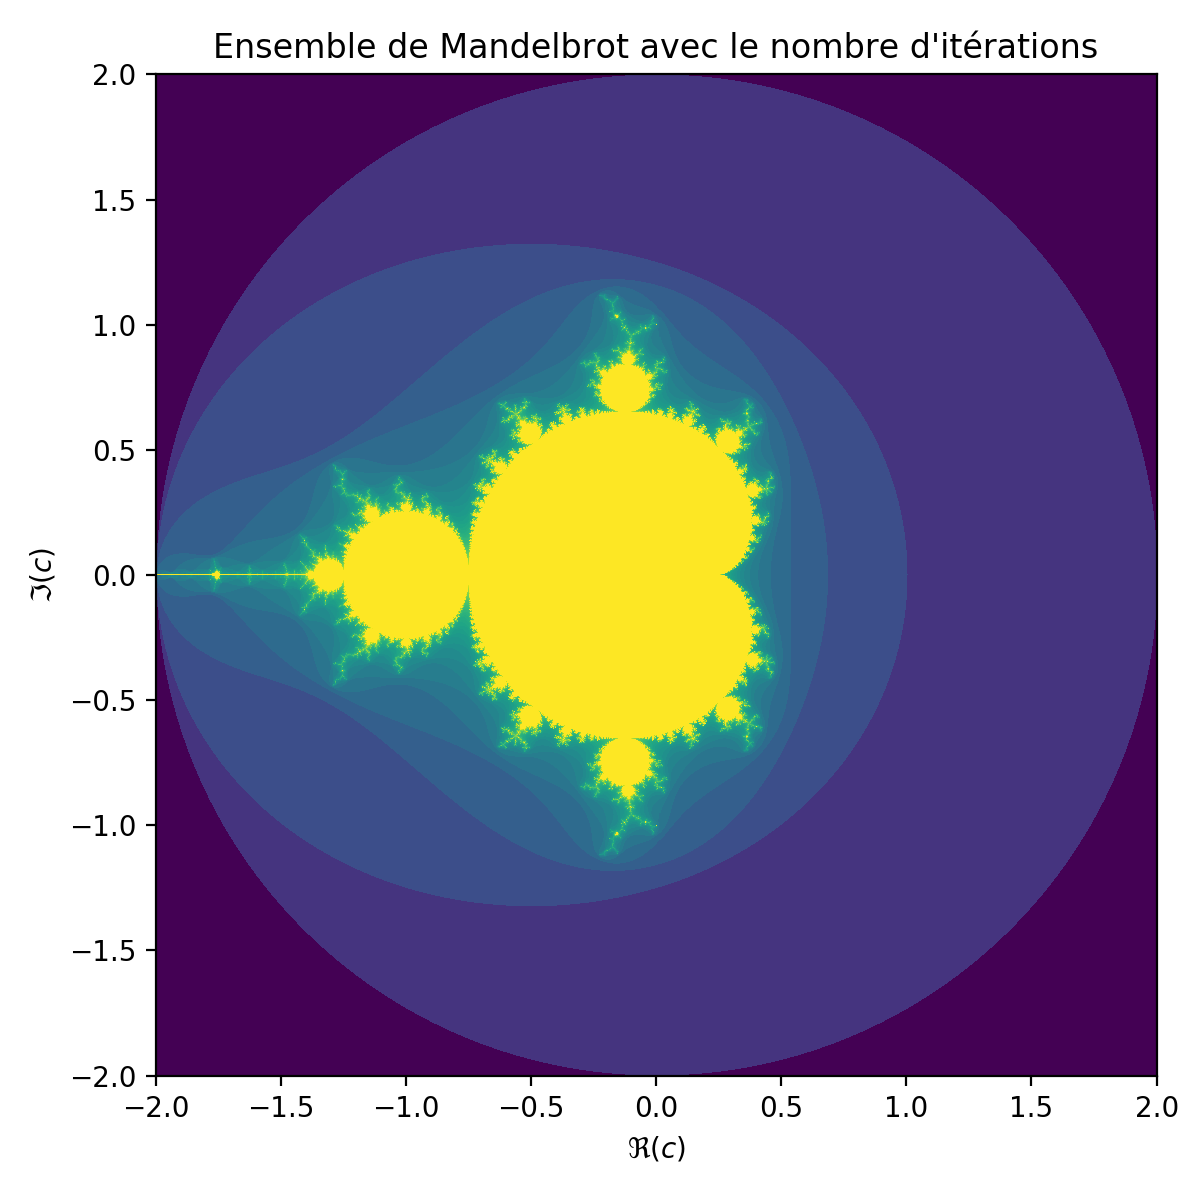</center>

**f)**
<span style="color:red">[bonus]</span> La méthode précédente a le désavantage de procéder séquentiellement au calcul pour chaque valeur de $c$, ce qui rend l'évaluation assez lente. Proposer une nouvelle implémentation permettant de calculer parallèlement toutes les valeurs en utilisant les indexages Numpy.

**Solution:**
L'idée est d'itérer tout le tableau correspondant à la grille en même temps, à l'exception des valeurs ayant déjà divergé:

In [ ]:
def mandelbrot_plot(N, max=1000):
    # construction de la grille
    lst = np.linspace(-2,2,N)
    x, y = np.meshgrid(lst,lst)
    c = x + 1j*y

    # tableau pour la représentation graphique
    out = np.zeros_like(c, dtype=float)
    # itérations
    z = np.zeros_like(c, dtype=complex)
    # tableau de booléens des z n'ayant pas divergé
    cond = np.abs(z) <= 2
    # itérations
    for i in range(1,max+1):
        # itération sur les z n'ayant pas divergé
        z[cond] = z[cond]**2 + c[cond]
        # met à jour la condition
        cond[cond] = np.abs(z[cond]) <= 2
        # ajoute le logarithme pour les z ayant divergé à cette itération
        div = np.logical_and(~cond,out==0)
        out[div] = np.log(i)
    # ajoute le logarithme pour les z restant
    out[cond] = np.log(max)

    # représentation graphique
    plt.figure(figsize=(6,6))
    plt.title("Ensemble de Mandelbrot avec le nombre d'itérations")
    plt.xlabel(r"$\Re(c)$")
    plt.ylabel(r"$\Im(c)$")
    plt.imshow(out, extent=[-2,2,-2,2])

# Exercice 3: Théorème central limite

Le théorème central limite (aussi appelé théorème limite central, théorème de la limite centrale ou théorème de la limite centrée) établit la convergence en loi de la somme d'une suite de variables aléatoires vers la loi normale. Intuitivement, ce résultat affirme qu'une somme de variables aléatoires identiques et indépendantes tend (sous certaines conditions) vers une variable aléatoire gaussienne.

Voici une formulation de ce théorème :

>**Théorème.**
Soit $(X_n)$ une suite de variables aléatoires réelles indépendantes et de même loi admettant une espérance $\mu$ et un écart-type $\sigma \ne 0$.
Soit $(\bar{X}_n)$ la suites définie par $\displaystyle \bar{X}_n = \frac{1}{n} \sum_{k=1}^n X_k$.
Pour $n$ assez grand, la loi de $\bar{X}_n$ peut être approché par la loi normale $\mathcal{N}(\mu, \frac{\sigma^2}{n})$.

L'objectif de cet exercice est de vérifier si ce théorème est valable pour différentes lois de probabilité :

* **Loi de Poisson**: distribution discrète sur $\mathbb{N}$, de paramètre $\lambda$, définie par :

$$
\displaystyle \mathbb{P}(X = k) = \exp(-\lambda) \frac{\lambda^k}{k!}\,, \quad \forall k \in \mathbb{N} \,.
$$

* **Loi normale**: distribution continue sur $\mathbb{R}$, de paramètres $m$ et $\sigma$, définie par la densité :

$$
\displaystyle \frac{1}{\sqrt{2\pi\sigma^2}} \exp\left( - \frac{(x-m)^2}{2\sigma^2} \right)\,, \quad \forall x \in \mathbb{R} \,.
$$

* **Loi de Cauchy**: distribution continue sur $\mathbb{R}$, de paramètres $a$ et $\gamma$, définie par la densité :

$$
\displaystyle \frac{1}{\pi\gamma\left(1 + \left(\frac{x-a}{\gamma}\right)^2\right)}\,, \quad \forall x \in \mathbb{R} \,.
$$

**a)**
Définir une fonction `densite_loi_normale(x, mu var)` prenant comme un argument :
* `x` (tableau) : un tableau de nombres flottants

* `mu` (nombre flottant) : moyenne

* `var` (nombre flottant strictement positif) : variance $\sigma^2$

et qui renvoie la densité de la loi normale évaluée pour chaque nombre $x$ dans `x`:

$$
\mathcal{N}(\mu, \sigma^2) = \frac{1}{\sqrt{2\pi\sigma^2}} \exp\left( - \frac{(x-\mu)^2}{2\sigma^2} \right) \,.
$$


**Solution:**
Il s'agit essentiellement de recopier la formule en utilisant les fonctions de Numpy:

In [ ]:
def densite_loi_normale(x, mu, var):
    return 1 / (np.sqrt(2*np.pi*var)) * np.exp(-(x-mu)**2 / (2*var))



**b)**
Regarder la documentation de la fonction [`numpy.random.poisson`](https://numpy.org/doc/stable/reference/random/generated/numpy.random.poisson.html) et générer 10 valeurs aléatoires selon une loi de Poisson de paramètre $\lambda = 2$.

**Solution:**
La documentation fournit toutes les informations:

In [ ]:
np.random.poisson(lam=2, size=10)



**c)**
Écrire une fonction `generer_echantillons_poisson(lam, N, M)` qui prend en arguments :
* `lam` (réel strictement positif): paramètre $\lambda$ pour la loi de Poisson

* `N` (entier strictement positif): nombre d'expériences

* `M` (entier strictement positif): nombre de variables aléatoires générées pour chaque expérience

et qui génère `N` expériences avec `M` variables aléatoires générées par expérience, et qui renvoie :
* (nombre flottant) : la valeur moyenne sur les `N * M` variables aléatoires générées,

* (nombre flottant): l'écart-type sur les `N * M` variables aléatoires générées,

* (tableau) : vecteur numpy (*i.e.* un tableau de taille `(N,)`) où chaque élément est la moyenne des variables aléatoires d'une expérience.

Pour les valeurs `lam=2` et `N=10000`, exécuter `generer_echantillons_poisson(lam, N, M)` pour $M \in \{10, 100, 1000\}$ et sauvegarder les résultats dans des variables.

**Solution:**
Il s'agit d'utiliser la fonction `mean` avec l'argument `axis=1` pour faire la moyenne sur la seconde dimension:

In [ ]:
def generer_echantillons_poisson(lam, N, M):
    sim = np.random.poisson(lam=lam, size=(N, M))
    return sim.mean(), sim.std(), sim.mean(axis=1)

lam = 2 ; N = 10000 ; Mliste = (10,100,1000)
poisson = [generer_echantillons_poisson(lam, N, M) for M in Mliste]



**d)**
Pour chaque valeur de `M`, afficher la distribution du vecteur numpy contenant les moyennes de chaque expérience, ainsi que la distribution de la loi normale attendue si la théorème central limite est vérifié. On pourra utiliser la fonction [`matplotlib.pyplot.hist`](https://numpy.org/doc/stable/reference/generated/numpy.histogram.html) pour afficher l'histogramme d'un tableau, avec le paramètre `bins=50` pour fixer le nombre colonnes et `density=True` pour afficher une distribution de probabilité. On utilisera les moyennes et les écart-types empiriques renvoyés par la fonction `generer_echantillons_poisson` pour les paramètres de la loi normale.
Choisir des valeurs pertinentes pour les valeurs limites de l'axe des abscisses. Faire une hypothèse sur la validité du théorème central limite pour la loi de Poisson.

**Solution:**
Il s'agit de reprendre les données générées précédemment puis de tracer l'histogramme et la loi normale avec les paramètres empirique de moyenne et écart-type:

In [ ]:
plt.figure(figsize=(14, 4))
for i,result in enumerate(poisson):
        plt.subplot(1, 3, i+1)
        M = Mliste[i]
        mean,std,data = result
        rstd = std/np.sqrt(M) # écart-type renormalisé
        plt.title(f"M = {M}")
        plt.hist(data, bins=50, density=True)
        x = np.linspace(0, 4, 501)
        y = densite_loi_normale(x, mean, rstd**2)
        plt.plot(x, y)
        plt.xlim((2-5*rstd,2+5*rstd))

La conclusion semble que le théorème central limite est satisfait pour la loi de Poisson.

**e)**
Reprendre les questions **c)** et **d)** pour la loi normale. Pour cela utiliser la fonction [`numpy.random.normal`](https://numpy.org/doc/stable/reference/random/generated/numpy.random.normal.html), générer des moyennes pour `loc=2`, `scale=1`, `N=10000` et $M \in \{10, 100, 1000\}$. Tracer les histogrammes et faire une hypothèse sur la validité du théorème central limite pour la loi normale.

**Solution:**
La première étape consisite à générer les échantillons:

In [ ]:
def generer_echantillons_normal(loc, scale, N, M):
    sim = np.random.normal(loc=loc, scale=scale, size=(N, M))
    return sim.mean(), sim.std(), sim.mean(axis=1)

loc = 2 ; scale = 1
normal = [generer_echantillons_normal(loc, scale, N, M) for M in Mliste]

La seconde étape est identique:

In [ ]:
plt.figure(figsize=(14, 4))
for i,result in enumerate(normal):
        plt.subplot(1, 3, i+1)
        M = Mliste[i]
        plt.title(f"M = {M}")
        mean,std,data = result
        rstd = std/np.sqrt(M)
        plt.hist(data, bins=50, density=True)
        x = np.linspace(0, 4, 501)
        y = densite_loi_normale(x, mean, rstd**2)
        plt.plot(x, y)
        plt.xlim((2-5*rstd,2+5*rstd))

La conclusion est que le théorème central limite semble très bien vérifié pour la loi de normale.

**f)**
Reprendre les questions **c)** et **d)** pour la loi de Cauchy avec $a=0$ et $\gamma=1$. Pour cela utiliser la fonction [`numpy.random.standard_cauchy`](https://numpy.org/doc/stable/reference/random/generated/numpy.random.standard_cauchy.html). Utiliser `bins=np.arange(-10, 10.1, 0.1)` et faire une hypothèse sur la validité du théorème central limite pour la loi de Cauchy.

**Solution:**
La première étape est pratiquement identique:

In [ ]:
def generer_echantillons_cauchy(N, M):
    sim = np.random.standard_cauchy(size=(N, M))
    return sim.mean(), sim.std(), sim.mean(axis=1)
    
cauchy = [generer_echantillons_cauchy(N, M) for M in Mliste]

Pour tracer les histogrammes avec des intervalles de longeur 0.1, il faut mettre les bins explicitement:

In [ ]:
plt.figure(figsize=(14, 4))
for i,result in enumerate(cauchy):
        plt.subplot(1, 3, i+1)
        M = Mliste[i]
        plt.title(f"M = {M}")
        mean,std,data = result
        rstd = std/np.sqrt(M)
        plt.hist(data, bins=np.arange(-10, 10.1, 0.1), density=True)
        x = np.linspace(0, 4, 501)
        y = densite_loi_normale(x, mean, rstd**2)
        plt.plot(x, y)

Ces résultats semblent indiquer que le théorème central limite n'est pas valide pour la loi de Cauchy. C'est effectivement le cas, car la loi de Cauchy n'a pas d'espérence, donc même la loi faible des grands nombres n'est pas valide.

